In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/uci_to_p02_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]
LABEL_COLUMNS = ["split", "activity", "participant", "position", "platform", "recording_id"]

# Read in the feature sets 
uci = pd.read_csv("../../data/processed/uci/uci_features.csv")
group = pd.read_csv("../../data/processed/group/group_features.csv")
FEATURES = [column for column in uci.columns if column not in LABEL_COLUMNS]

# Split the training and test data
uci_train = uci[uci["split"] == "train"]
uci_test = uci[uci["split"] == "test"]
p02 = group[group["participant"] == "P02"]

print(f"UCI train: {len(uci_train):,} windows (21 volunteers)")
print(f"UCI test:  {len(uci_test):,} windows (9 new volunteers)")
print(f"P02:       {len(p02):,} windows (waist)")
print("Same columns in both files:", list(uci.columns) == list(group.columns))

UCI train: 3,285 windows (21 volunteers)
UCI test:  1,387 windows (9 new volunteers)
P02:       7,759 windows (waist)
Same columns in both files: True


In [4]:
def undersample_walking(X_train, y_train):
   # Keep only as many walking windows as the largest stairs activity (for kNN).
    is_walking = y_train == "walking"
    number_to_keep = y_train[~is_walking].value_counts().max()
    kept_walking = y_train[is_walking].sample(n=number_to_keep, random_state=42).index
    keep = y_train.index.isin(kept_walking) | ~is_walking
    return X_train[keep], y_train[keep]


def train_model(model_name, X_train, y_train):
    # Train LR, RF and kNN. Returns the model and its scaler (RF doesn't need one).
    if model_name == "RF":
        model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
        model.fit(X_train, y_train)
        return model, None

    if model_name == "kNN":
        X_train, y_train = undersample_walking(X_train, y_train)

    scaler = MinMaxScaler(feature_range=(-1, 1))
    X_train = scaler.fit_transform(X_train)            # scaling learned from UCI training data only
    if model_name == "LR":
        model = LogisticRegression(max_iter=2000, class_weight="balanced")
    else:
        model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)
    return model, scaler


def test_model(model, scaler, test_data, name, file_name):
    # Test a trained model, print the results and return the macro F1.
    X_test = test_data[FEATURES]
    y_test = test_data["activity"]
    if scaler is not None:
        X_test = scaler.transform(X_test)
    predictions = model.predict(X_test)

    macro_f1 = f1_score(y_test, predictions, average="macro", labels=ACTIVITIES, zero_division=0)
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(f"Macro F1: {macro_f1:.3f}\n")
    print(classification_report(y_test, predictions, labels=ACTIVITIES, digits=3, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=ACTIVITIES, normalize="true",
                                            cmap="Blues", xticks_rotation=30)
    plt.title(name)
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"{file_name}_confusion_matrix.png", dpi=150)
    plt.show()
    return macro_f1

===== LR: UCI train -> UCI test =====
Accuracy: 0.874
Macro F1: 0.873

                    precision    recall  f1-score   support

           walking      0.842     0.938     0.887       496
  walking_upstairs      0.933     0.794     0.858       471
walking_downstairs      0.859     0.888     0.874       420

          accuracy                          0.874      1387
         macro avg      0.878     0.873     0.873      1387
      weighted avg      0.878     0.874     0.873      1387



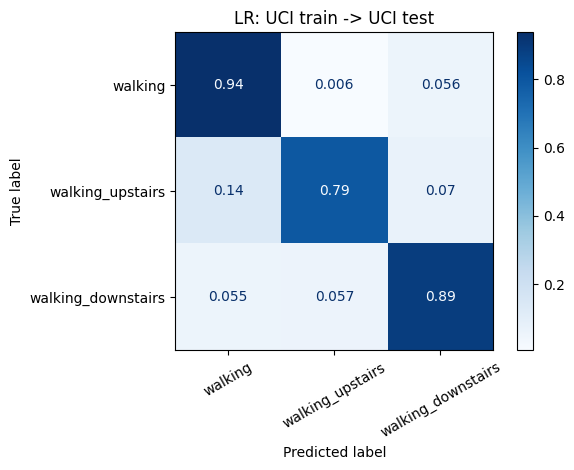

===== LR: UCI train -> P02 (waist) =====
Accuracy: 0.096
Macro F1: 0.058

                    precision    recall  f1-score   support

           walking      0.000     0.000     0.000      6399
  walking_upstairs      0.096     1.000     0.174       741
walking_downstairs      0.000     0.000     0.000       619

          accuracy                          0.096      7759
         macro avg      0.032     0.333     0.058      7759
      weighted avg      0.009     0.096     0.017      7759



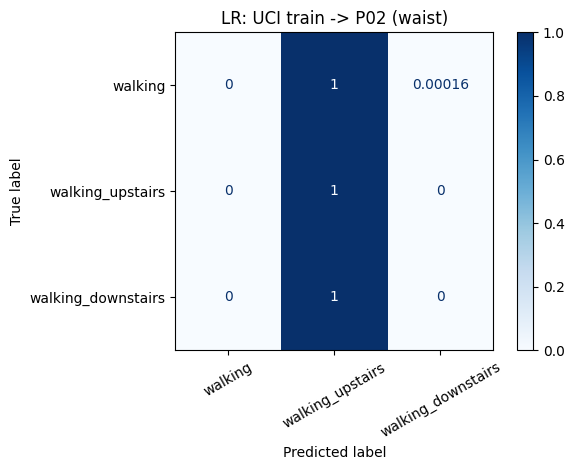

===== RF: UCI train -> UCI test =====
Accuracy: 0.891
Macro F1: 0.891

                    precision    recall  f1-score   support

           walking      0.870     0.927     0.898       496
  walking_upstairs      0.864     0.904     0.884       471
walking_downstairs      0.959     0.833     0.892       420

          accuracy                          0.891      1387
         macro avg      0.898     0.888     0.891      1387
      weighted avg      0.895     0.891     0.891      1387



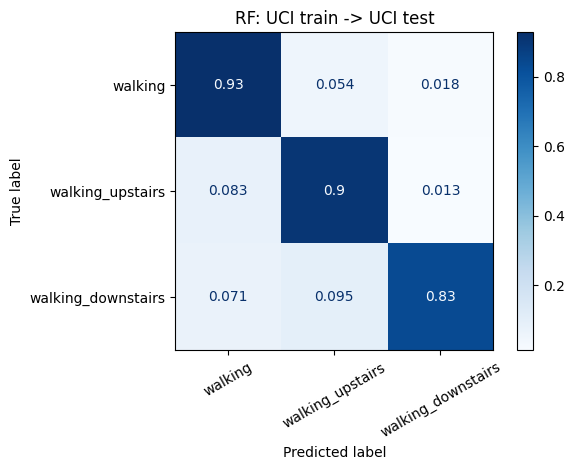

===== RF: UCI train -> P02 (waist) =====
Accuracy: 0.191
Macro F1: 0.156

                    precision    recall  f1-score   support

           walking      0.800     0.128     0.221      6399
  walking_upstairs      0.117     0.837     0.206       741
walking_downstairs      0.029     0.068     0.041       619

          accuracy                          0.191      7759
         macro avg      0.316     0.344     0.156      7759
      weighted avg      0.674     0.191     0.205      7759



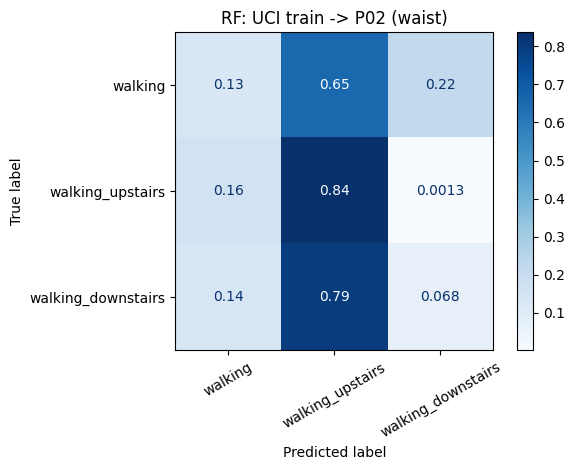

===== kNN: UCI train -> UCI test =====
Accuracy: 0.824
Macro F1: 0.825

                    precision    recall  f1-score   support

           walking      0.761     0.879     0.816       496
  walking_upstairs      0.854     0.809     0.831       471
walking_downstairs      0.886     0.776     0.827       420

          accuracy                          0.824      1387
         macro avg      0.834     0.821     0.825      1387
      weighted avg      0.830     0.824     0.824      1387



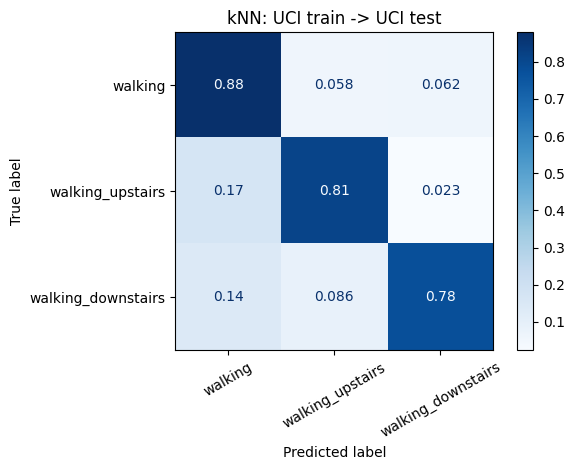

===== kNN: UCI train -> P02 (waist) =====
Accuracy: 0.097
Macro F1: 0.071

                    precision    recall  f1-score   support

           walking      0.000     0.000     0.000      6399
  walking_upstairs      0.098     0.997     0.178       741
walking_downstairs      0.071     0.023     0.034       619

          accuracy                          0.097      7759
         macro avg      0.056     0.340     0.071      7759
      weighted avg      0.015     0.097     0.020      7759



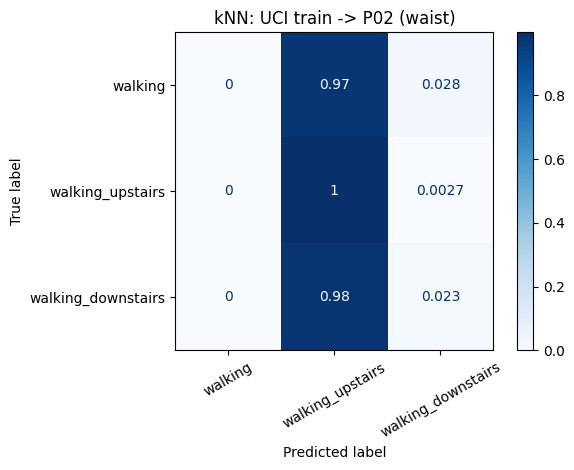

In [5]:
# Train on UCI and test on UCI and P02 (since they used waist position too)
uci_scores = {}
p02_scores = {}

for model_name in ["LR", "RF", "kNN"]:
    model, scaler = train_model(model_name, uci_train[FEATURES], uci_train["activity"])
    uci_scores[model_name] = test_model(model, scaler, uci_test,
                                        f"{model_name}: UCI train -> UCI test", f"{model_name}_uci_to_uci")
    p02_scores[model_name] = test_model(model, scaler, p02,
                                        f"{model_name}: UCI train -> P02 (waist)", f"{model_name}_uci_to_P02")

In [9]:
# Comparison table
LOPO_P02_SCORES = {"LR": 0.320, "RF": 0.303, "kNN": 0.280}

comparison = pd.DataFrame({
    "UCI test (new person)": uci_scores,
    "P02 (new person + phone)": p02_scores,
    "P02 leave-one-out (new person + phone + position)": LOPO_P02_SCORES,
}).round(3)

comparison.to_csv(RESULTS_FOLDER / "uci_to_p02_summary.csv")
comparison

,UCI test (new person),P02 (new person + phone),P02 leave-one-out (new person + phone + position)
LR,0.873,0.058,0.320
RF,0.891,0.156,0.303
kNN,0.825,0.071,0.280


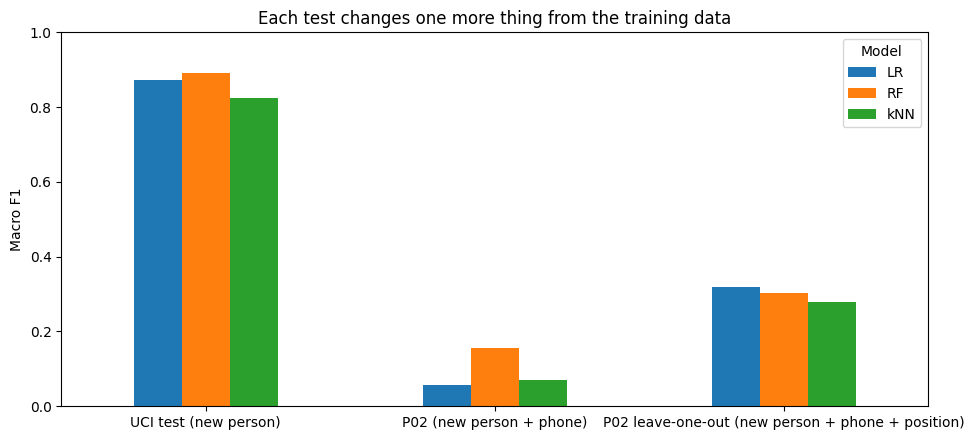

In [10]:
# Comparison chart
comparison.T.plot(kind="bar", figsize=(10, 4.5), ylim=(0, 1), rot=0)
plt.title("Each test changes one more thing from the training data")
plt.ylabel("Macro F1")
plt.legend(title="Model")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "uci_to_p02_comparison.png", dpi=150)
plt.show()